In [1]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import os
import random

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Upload Marathi Sarcasm Dataset

from google.colab import files

uploaded = files.upload()

print("File uploaded successfully!")

Saving final_sarcasm_dataset.csv to final_sarcasm_dataset.csv
File uploaded successfully!


In [3]:
# Step 3: Load Sarcasm Dataset

import pandas as pd

sarcasm_df = pd.read_csv("final_sarcasm_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", sarcasm_df.shape)

print("\nColumns:")
print(sarcasm_df.columns.tolist())

print("\nFirst 5 rows:")
display(sarcasm_df.head())

print("\nDataset information:")
sarcasm_df.info()

Dataset loaded successfully!
Shape: (5665, 5)

Columns:
['id', 'Label', 'clean_tweet_v2', 'text_length', 'word_count']

First 5 rows:


,id,Label,clean_tweet_v2,text_length,word_count
0,1,-1,मध्ये करत खरंच करत हेच कळत राव,30,7
1,2,-1,अबे येड्या कळतो तुला,20,4
2,3,-1,बरं झालं लिहिले आजच बावनकुळे असते तुमचे,39,7
3,4,-1,किव्वा चे द्यावे नमो च्या नावाने आहेच विमानतळ ...,105,18
4,5,-1,वी नापास नांगरगठ्ठ्या देशाचा पंतप्रधान होऊन बस...,146,21



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5665 entries, 0 to 5664
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              5665 non-null   int64 
 1   Label           5665 non-null   int64 
 2   clean_tweet_v2  5665 non-null   object
 3   text_length     5665 non-null   int64 
 4   word_count      5665 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 221.4+ KB


In [4]:
# Step 4: Dataset Quality Check

print("===== DATASET QUALITY CHECK =====")

# Missing values
print("\n1. Missing Values:")
print(sarcasm_df.isnull().sum())

# Duplicate rows
print("\n2. Duplicate Rows:")
print("Duplicate rows:", sarcasm_df.duplicated().sum())

# Duplicate text
print("\n3. Duplicate Text:")
print("Duplicate texts:", sarcasm_df["clean_tweet_v2"].duplicated().sum())

# Label distribution
print("\n4. Label Distribution:")
print(sarcasm_df["Label"].value_counts().sort_index())

# Unique labels
print("\n5. Unique Labels:")
print(sorted(sarcasm_df["Label"].unique()))

# Empty text
print("\n6. Empty Text:")
print(
    "Empty texts:",
    sarcasm_df["clean_tweet_v2"].astype(str).str.strip().eq("").sum()
)

# Text length statistics
print("\n7. Text Length Statistics:")
print(sarcasm_df["text_length"].describe())

===== DATASET QUALITY CHECK =====

1. Missing Values:
id                0
Label             0
clean_tweet_v2    0
text_length       0
word_count        0
dtype: int64

2. Duplicate Rows:
Duplicate rows: 0

3. Duplicate Text:
Duplicate texts: 0

4. Label Distribution:
Label
-1    3221
 1    2444
Name: count, dtype: int64

5. Unique Labels:
[np.int64(-1), np.int64(1)]

6. Empty Text:
Empty texts: 0

7. Text Length Statistics:
count    5665.000000
mean       61.944395
std        45.717393
min         2.000000
25%        32.000000
50%        49.000000
75%        76.000000
max       265.000000
Name: text_length, dtype: float64


In [5]:
# Step 5: Prepare Binary Sarcasm Labels

sarcasm_df = sarcasm_df.copy()

# Convert original labels
sarcasm_df["label"] = sarcasm_df["Label"].map({
    -1: 0,
     1: 1
})

# Label names
label_names = {
    0: "Non-Sarcastic",
    1: "Sarcastic"
}

# Check for any mapping problems
print("Missing labels after mapping:",
      sarcasm_df["label"].isnull().sum())

print("\nLabel mapping:")
print(label_names)

print("\nFinal label distribution:")
print(sarcasm_df["label"].value_counts().sort_index())

print("\nFinal dataset shape:")
print(sarcasm_df.shape)

Missing labels after mapping: 0

Label mapping:
{0: 'Non-Sarcastic', 1: 'Sarcastic'}

Final label distribution:
label
0    3221
1    2444
Name: count, dtype: int64

Final dataset shape:
(5665, 6)


In [6]:
# Step 6: Train / Validation / Test Split

from sklearn.model_selection import train_test_split

# Keep only the columns needed for Transformer training
sarcasm_data = sarcasm_df[[
    "clean_tweet_v2",
    "label"
]].copy()

# First split: 80% training, 20% temporary
sarcasm_train_df, sarcasm_temp_df = train_test_split(
    sarcasm_data,
    test_size=0.20,
    random_state=42,
    stratify=sarcasm_data["label"]
)

# Second split: 10% validation, 10% test
sarcasm_val_df, sarcasm_test_df = train_test_split(
    sarcasm_temp_df,
    test_size=0.50,
    random_state=42,
    stratify=sarcasm_temp_df["label"]
)

print("===== DATASET SPLIT =====")

print("Training samples:", len(sarcasm_train_df))
print("Validation samples:", len(sarcasm_val_df))
print("Testing samples:", len(sarcasm_test_df))

print("\nTraining label distribution:")
print(sarcasm_train_df["label"].value_counts().sort_index())

print("\nValidation label distribution:")
print(sarcasm_val_df["label"].value_counts().sort_index())

print("\nTesting label distribution:")
print(sarcasm_test_df["label"].value_counts().sort_index())

===== DATASET SPLIT =====
Training samples: 4532
Validation samples: 566
Testing samples: 567

Training label distribution:
label
0    2577
1    1955
Name: count, dtype: int64

Validation label distribution:
label
0    322
1    244
Name: count, dtype: int64

Testing label distribution:
label
0    322
1    245
Name: count, dtype: int64


In [7]:
# Step 7: Create Hugging Face Datasets

from datasets import Dataset

sarcasm_train_dataset = Dataset.from_pandas(
    sarcasm_train_df,
    preserve_index=False
)

sarcasm_val_dataset = Dataset.from_pandas(
    sarcasm_val_df,
    preserve_index=False
)

sarcasm_test_dataset = Dataset.from_pandas(
    sarcasm_test_df,
    preserve_index=False
)

print("Sarcasm Hugging Face datasets created successfully!")

print("\nTrain dataset:")
print(sarcasm_train_dataset)

print("\nValidation dataset:")
print(sarcasm_val_dataset)

print("\nTest dataset:")
print(sarcasm_test_dataset)

Sarcasm Hugging Face datasets created successfully!

Train dataset:
Dataset({
    features: ['clean_tweet_v2', 'label'],
    num_rows: 4532
})

Validation dataset:
Dataset({
    features: ['clean_tweet_v2', 'label'],
    num_rows: 566
})

Test dataset:
Dataset({
    features: ['clean_tweet_v2', 'label'],
    num_rows: 567
})


In [8]:
# Step 8: Load BERT Tokenizer and Model

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

BERT_MODEL_NAME = "bert-base-uncased"

NUM_LABELS = 2

sarcasm_bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME
)

sarcasm_bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Non-Sarcastic",
        1: "Sarcastic"
    },
    label2id={
        "Non-Sarcastic": 0,
        "Sarcastic": 1
    }
)

print("BERT loaded successfully!")
print("Model:", BERT_MODEL_NAME)
print("Number of labels:", NUM_LABELS)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT loaded successfully!
Model: bert-base-uncased
Number of labels: 2


In [9]:
# Step 9: BERT Tokenization

def sarcasm_bert_tokenize_function(examples):
    return sarcasm_bert_tokenizer(
        examples["clean_tweet_v2"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

sarcasm_bert_train_tokenized = sarcasm_train_dataset.map(
    sarcasm_bert_tokenize_function,
    batched=True
)

sarcasm_bert_val_tokenized = sarcasm_val_dataset.map(
    sarcasm_bert_tokenize_function,
    batched=True
)

sarcasm_bert_test_tokenized = sarcasm_test_dataset.map(
    sarcasm_bert_tokenize_function,
    batched=True
)

print("BERT tokenization completed!")

print("\nTrain features:")
print(sarcasm_bert_train_tokenized.features)

print("\nValidation features:")
print(sarcasm_bert_val_tokenized.features)

print("\nTest features:")
print(sarcasm_bert_test_tokenized.features)

Map:   0%|          | 0/4532 [00:00<?, ? examples/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

BERT tokenization completed!

Train features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Validation features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Test features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}


In [10]:
# Step 11: BERT Training Configuration

from transformers import TrainingArguments

sarcasm_bert_training_args = TrainingArguments(
    output_dir="./sarcasm_bert_training_output",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_strategy="epoch",

    report_to="none"
)

print("BERT training configuration created successfully!")
print("Epochs:", sarcasm_bert_training_args.num_train_epochs)
print(
    "Train batch size:",
    sarcasm_bert_training_args.per_device_train_batch_size
)
print("Learning rate:", sarcasm_bert_training_args.learning_rate)

BERT training configuration created successfully!
Epochs: 3
Train batch size: 8
Learning rate: 2e-05


In [12]:
# Step 12A: Sarcasm Evaluation Metrics

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # Get predicted class
    predictions = np.argmax(predictions, axis=1)

    # Calculate metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Sarcasm evaluation metrics created successfully!")

Sarcasm evaluation metrics created successfully!


In [13]:
# Step 12B: Create BERT Trainer

from transformers import Trainer

sarcasm_bert_trainer = Trainer(
    model=sarcasm_bert_model,
    args=sarcasm_bert_training_args,
    train_dataset=sarcasm_bert_train_tokenized,
    eval_dataset=sarcasm_bert_val_tokenized,
    processing_class=sarcasm_bert_tokenizer,
    compute_metrics=compute_metrics
)

print("BERT Trainer created successfully!")

BERT Trainer created successfully!


In [14]:
# Step 13: Check GPU

import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA: 12.8
GPU available: True
GPU: Tesla T4


In [15]:
# Step 14: Train BERT

print("Starting BERT training...\n")

sarcasm_bert_train_result = sarcasm_bert_trainer.train()

print("\nBERT training completed successfully!")

Starting BERT training...



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.352767,0.318311,0.869258,0.892087,0.869258,0.864517
2,0.309745,0.329509,0.869258,0.892087,0.869258,0.864517
3,0.269609,0.288996,0.869258,0.879470,0.869258,0.866345


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


BERT training completed successfully!


In [16]:
# Step 15: Evaluate BERT on Test Dataset

print("Evaluating BERT on test dataset...\n")

bert_test_results = sarcasm_bert_trainer.evaluate(
    sarcasm_bert_test_tokenized
)

print("\n===== BERT Test Results =====")

for key, value in bert_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Evaluating BERT on test dataset...



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.269609,0.243124,3,0.888889,0.896147,0.888889,0.887022



===== BERT Test Results =====
eval_loss: 0.2431
eval_accuracy: 0.8889
eval_precision: 0.8961
eval_recall: 0.8889
eval_f1: 0.8870


In [17]:
# Step 16: BERT Classification Report and Confusion Matrix

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Generating BERT predictions...\n")

bert_predictions_output = sarcasm_bert_trainer.predict(
    sarcasm_bert_test_tokenized
)

bert_predictions = np.argmax(
    bert_predictions_output.predictions,
    axis=1
)

bert_true_labels = bert_predictions_output.label_ids

print("===== BERT Classification Report =====")

print(
    classification_report(
        bert_true_labels,
        bert_predictions,
        target_names=[
            "Non-Sarcastic",
            "Sarcastic"
        ],
        digits=4
    )
)

print("===== BERT Confusion Matrix =====")

bert_cm = confusion_matrix(
    bert_true_labels,
    bert_predictions
)

print(bert_cm)

Generating BERT predictions...



===== BERT Classification Report =====
               precision    recall  f1-score   support

Non-Sarcastic     0.8548    0.9689    0.9083       322
    Sarcastic     0.9505    0.7837    0.8591       245

     accuracy                         0.8889       567
    macro avg     0.9026    0.8763    0.8837       567
 weighted avg     0.8961    0.8889    0.8870       567

===== BERT Confusion Matrix =====
[[312  10]
 [ 53 192]]


In [18]:
# Step 17: Save BERT Sarcasm Model

sarcasm_bert_model_path = "./sarcasm_bert_model"

sarcasm_bert_trainer.save_model(
    sarcasm_bert_model_path
)

sarcasm_bert_tokenizer.save_pretrained(
    sarcasm_bert_model_path
)

print("BERT sarcasm model saved successfully!")
print("Location:", sarcasm_bert_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT sarcasm model saved successfully!
Location: ./sarcasm_bert_model


In [19]:
# Step 18: Load mBERT Tokenizer and Model

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MBERT_MODEL_NAME = "bert-base-multilingual-cased"

NUM_LABELS = 2

sarcasm_mbert_tokenizer = AutoTokenizer.from_pretrained(
    MBERT_MODEL_NAME
)

sarcasm_mbert_model = AutoModelForSequenceClassification.from_pretrained(
    MBERT_MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Non-Sarcastic",
        1: "Sarcastic"
    },
    label2id={
        "Non-Sarcastic": 0,
        "Sarcastic": 1
    }
)

print("mBERT loaded successfully!")
print("Model:", MBERT_MODEL_NAME)
print("Number of labels:", NUM_LABELS)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


mBERT loaded successfully!
Model: bert-base-multilingual-cased
Number of labels: 2


In [20]:
# Step 19: mBERT Tokenization

def sarcasm_mbert_tokenize_function(examples):
    return sarcasm_mbert_tokenizer(
        examples["clean_tweet_v2"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

sarcasm_mbert_train_tokenized = sarcasm_train_dataset.map(
    sarcasm_mbert_tokenize_function,
    batched=True
)

sarcasm_mbert_val_tokenized = sarcasm_val_dataset.map(
    sarcasm_mbert_tokenize_function,
    batched=True
)

sarcasm_mbert_test_tokenized = sarcasm_test_dataset.map(
    sarcasm_mbert_tokenize_function,
    batched=True
)

print("mBERT tokenization completed!")

print("\nTrain features:")
print(sarcasm_mbert_train_tokenized.features)

print("\nValidation features:")
print(sarcasm_mbert_val_tokenized.features)

print("\nTest features:")
print(sarcasm_mbert_test_tokenized.features)

Map:   0%|          | 0/4532 [00:00<?, ? examples/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

mBERT tokenization completed!

Train features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Validation features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Test features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}


In [21]:
# Step 20: Prepare mBERT Datasets

sarcasm_mbert_train_tokenized = sarcasm_mbert_train_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_mbert_val_tokenized = sarcasm_mbert_val_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_mbert_test_tokenized = sarcasm_mbert_test_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_mbert_train_tokenized.set_format("torch")
sarcasm_mbert_val_tokenized.set_format("torch")
sarcasm_mbert_test_tokenized.set_format("torch")

print("mBERT datasets prepared successfully!")

print(
    "Train columns:",
    sarcasm_mbert_train_tokenized.column_names
)

print(
    "Validation columns:",
    sarcasm_mbert_val_tokenized.column_names
)

print(
    "Test columns:",
    sarcasm_mbert_test_tokenized.column_names
)

mBERT datasets prepared successfully!
Train columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Validation columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Test columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [22]:
# Step 21: mBERT Training Configuration

from transformers import TrainingArguments

sarcasm_mbert_training_args = TrainingArguments(
    output_dir="./sarcasm_mbert_training_output",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_strategy="epoch",

    report_to="none"
)

print("mBERT training configuration created successfully!")
print("Epochs:", sarcasm_mbert_training_args.num_train_epochs)
print(
    "Train batch size:",
    sarcasm_mbert_training_args.per_device_train_batch_size
)
print("Learning rate:", sarcasm_mbert_training_args.learning_rate)

mBERT training configuration created successfully!
Epochs: 3
Train batch size: 8
Learning rate: 2e-05


In [23]:
# Step 22: Create mBERT Trainer

from transformers import Trainer

sarcasm_mbert_trainer = Trainer(
    model=sarcasm_mbert_model,
    args=sarcasm_mbert_training_args,
    train_dataset=sarcasm_mbert_train_tokenized,
    eval_dataset=sarcasm_mbert_val_tokenized,
    processing_class=sarcasm_mbert_tokenizer,
    compute_metrics=compute_metrics
)

print("mBERT Trainer created successfully!")

mBERT Trainer created successfully!


In [25]:
# Step 23A: Fix torchvision compatibility issue

import sys

# Remove torchvision from the current Python session
if "torchvision" in sys.modules:
    del sys.modules["torchvision"]

# Tell Hugging Face Datasets not to use torchvision
import datasets

datasets.config.TORCHVISION_AVAILABLE = False

print("Torchvision disabled successfully!")

Torchvision disabled successfully!


In [26]:
# Verify the fix

print("Torchvision available in Datasets:",
      datasets.config.TORCHVISION_AVAILABLE)

Torchvision available in Datasets: False


In [27]:
# Step 23B: Train mBERT

print("Starting mBERT training...\n")

sarcasm_mbert_train_result = sarcasm_mbert_trainer.train()

print("\nmBERT training completed successfully!")

Starting mBERT training...



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.366781,0.344324,0.869258,0.892087,0.869258,0.864517
2,0.278939,0.292224,0.879859,0.879973,0.879859,0.879363
3,0.223078,0.403506,0.892226,0.894982,0.892226,0.891144


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


mBERT training completed successfully!


In [28]:
# Step 24: Evaluate mBERT on Test Dataset

print("Evaluating mBERT on test dataset...\n")

mbert_test_results = sarcasm_mbert_trainer.evaluate(
    sarcasm_mbert_test_tokenized
)

print("\n===== mBERT Test Results =====")

for key, value in mbert_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Evaluating mBERT on test dataset...



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.223078,0.313040,3,0.908289,0.908683,0.908289,0.907916



===== mBERT Test Results =====
eval_loss: 0.3130
eval_accuracy: 0.9083
eval_precision: 0.9087
eval_recall: 0.9083
eval_f1: 0.9079


In [29]:
# Step 25: mBERT Classification Report and Confusion Matrix

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Generating mBERT predictions...\n")

mbert_predictions_output = sarcasm_mbert_trainer.predict(
    sarcasm_mbert_test_tokenized
)

mbert_predictions = np.argmax(
    mbert_predictions_output.predictions,
    axis=1
)

mbert_true_labels = mbert_predictions_output.label_ids

print("===== mBERT Classification Report =====")

print(
    classification_report(
        mbert_true_labels,
        mbert_predictions,
        target_names=[
            "Non-Sarcastic",
            "Sarcastic"
        ],
        digits=4
    )
)

print("===== mBERT Confusion Matrix =====")

mbert_cm = confusion_matrix(
    mbert_true_labels,
    mbert_predictions
)

print(mbert_cm)

Generating mBERT predictions...



===== mBERT Classification Report =====
               precision    recall  f1-score   support

Non-Sarcastic     0.9018    0.9410    0.9210       322
    Sarcastic     0.9177    0.8653    0.8908       245

     accuracy                         0.9083       567
    macro avg     0.9098    0.9031    0.9059       567
 weighted avg     0.9087    0.9083    0.9079       567

===== mBERT Confusion Matrix =====
[[303  19]
 [ 33 212]]


In [30]:
# Step 26: Save mBERT Sarcasm Model

sarcasm_mbert_model_path = "./sarcasm_mbert_model"

sarcasm_mbert_trainer.save_model(
    sarcasm_mbert_model_path
)

sarcasm_mbert_tokenizer.save_pretrained(
    sarcasm_mbert_model_path
)

print("mBERT sarcasm model saved successfully!")
print("Location:", sarcasm_mbert_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

mBERT sarcasm model saved successfully!
Location: ./sarcasm_mbert_model


In [31]:
# Step 27: Load RoBERTa Tokenizer and Model

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

ROBERTA_MODEL_NAME = "roberta-base"

NUM_LABELS = 2

sarcasm_roberta_tokenizer = AutoTokenizer.from_pretrained(
    ROBERTA_MODEL_NAME
)

sarcasm_roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Non-Sarcastic",
        1: "Sarcastic"
    },
    label2id={
        "Non-Sarcastic": 0,
        "Sarcastic": 1
    }
)

print("RoBERTa loaded successfully!")
print("Model:", ROBERTA_MODEL_NAME)
print("Number of labels:", NUM_LABELS)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa loaded successfully!
Model: roberta-base
Number of labels: 2


In [32]:
# Step 28: RoBERTa Tokenization

def sarcasm_roberta_tokenize_function(examples):
    return sarcasm_roberta_tokenizer(
        examples["clean_tweet_v2"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

sarcasm_roberta_train_tokenized = sarcasm_train_dataset.map(
    sarcasm_roberta_tokenize_function,
    batched=True
)

sarcasm_roberta_val_tokenized = sarcasm_val_dataset.map(
    sarcasm_roberta_tokenize_function,
    batched=True
)

sarcasm_roberta_test_tokenized = sarcasm_test_dataset.map(
    sarcasm_roberta_tokenize_function,
    batched=True
)

print("RoBERTa tokenization completed!")

print("\nTrain features:")
print(sarcasm_roberta_train_tokenized.features)

print("\nValidation features:")
print(sarcasm_roberta_val_tokenized.features)

print("\nTest features:")
print(sarcasm_roberta_test_tokenized.features)

Map:   0%|          | 0/4532 [00:00<?, ? examples/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

RoBERTa tokenization completed!

Train features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}

Validation features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}

Test features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}


In [33]:
# Step 29: Prepare RoBERTa Datasets

sarcasm_roberta_train_tokenized = sarcasm_roberta_train_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_roberta_val_tokenized = sarcasm_roberta_val_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_roberta_test_tokenized = sarcasm_roberta_test_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_roberta_train_tokenized.set_format("torch")
sarcasm_roberta_val_tokenized.set_format("torch")
sarcasm_roberta_test_tokenized.set_format("torch")

print("RoBERTa datasets prepared successfully!")

print(
    "Train columns:",
    sarcasm_roberta_train_tokenized.column_names
)

print(
    "Validation columns:",
    sarcasm_roberta_val_tokenized.column_names
)

print(
    "Test columns:",
    sarcasm_roberta_test_tokenized.column_names
)

RoBERTa datasets prepared successfully!
Train columns: ['label', 'input_ids', 'attention_mask']
Validation columns: ['label', 'input_ids', 'attention_mask']
Test columns: ['label', 'input_ids', 'attention_mask']


In [34]:
# Step 30: RoBERTa Training Configuration

from transformers import TrainingArguments

sarcasm_roberta_training_args = TrainingArguments(
    output_dir="./sarcasm_roberta_training_output",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_strategy="epoch",

    report_to="none"
)

print("RoBERTa training configuration created successfully!")
print("Epochs:", sarcasm_roberta_training_args.num_train_epochs)
print(
    "Train batch size:",
    sarcasm_roberta_training_args.per_device_train_batch_size
)
print("Learning rate:", sarcasm_roberta_training_args.learning_rate)

RoBERTa training configuration created successfully!
Epochs: 3
Train batch size: 8
Learning rate: 2e-05


In [35]:
# Step 31: Create RoBERTa Trainer

from transformers import Trainer

sarcasm_roberta_trainer = Trainer(
    model=sarcasm_roberta_model,
    args=sarcasm_roberta_training_args,
    train_dataset=sarcasm_roberta_train_tokenized,
    eval_dataset=sarcasm_roberta_val_tokenized,
    processing_class=sarcasm_roberta_tokenizer,
    compute_metrics=compute_metrics
)

print("RoBERTa Trainer created successfully!")

RoBERTa Trainer created successfully!


In [36]:
# Step 32: Train RoBERTa

print("Starting RoBERTa training...\n")

sarcasm_roberta_train_result = sarcasm_roberta_trainer.train()

print("\nRoBERTa training completed successfully!")

Starting RoBERTa training...



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.371153,0.348130,0.867491,0.889342,0.867491,0.862790
2,0.344579,0.298658,0.846290,0.852770,0.846290,0.846994
3,0.303251,0.298809,0.871025,0.887609,0.871025,0.867212


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


RoBERTa training completed successfully!


In [37]:
# Step 33: Evaluate RoBERTa on Test Dataset

print("Evaluating RoBERTa on test dataset...\n")

roberta_test_results = sarcasm_roberta_trainer.evaluate(
    sarcasm_roberta_test_tokenized
)

print("\n===== RoBERTa Test Results =====")

for key, value in roberta_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Evaluating RoBERTa on test dataset...



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.303251,0.287011,3,0.887125,0.898497,0.887125,0.884641



===== RoBERTa Test Results =====
eval_loss: 0.2870
eval_accuracy: 0.8871
eval_precision: 0.8985
eval_recall: 0.8871
eval_f1: 0.8846


In [38]:
# Step 34: RoBERTa Classification Report and Confusion Matrix

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Generating RoBERTa predictions...\n")

roberta_predictions_output = sarcasm_roberta_trainer.predict(
    sarcasm_roberta_test_tokenized
)

roberta_predictions = np.argmax(
    roberta_predictions_output.predictions,
    axis=1
)

roberta_true_labels = roberta_predictions_output.label_ids

print("===== RoBERTa Classification Report =====")

print(
    classification_report(
        roberta_true_labels,
        roberta_predictions,
        target_names=[
            "Non-Sarcastic",
            "Sarcastic"
        ],
        digits=4
    )
)

print("===== RoBERTa Confusion Matrix =====")

roberta_cm = confusion_matrix(
    roberta_true_labels,
    roberta_predictions
)

print(roberta_cm)

Generating RoBERTa predictions...



===== RoBERTa Classification Report =====
               precision    recall  f1-score   support

Non-Sarcastic     0.8449    0.9814    0.9080       322
    Sarcastic     0.9689    0.7633    0.8539       245

     accuracy                         0.8871       567
    macro avg     0.9069    0.8723    0.8810       567
 weighted avg     0.8985    0.8871    0.8846       567

===== RoBERTa Confusion Matrix =====
[[316   6]
 [ 58 187]]


In [39]:
# Step 35: Save RoBERTa Sarcasm Model

sarcasm_roberta_model_path = "./sarcasm_roberta_model"

sarcasm_roberta_trainer.save_model(
    sarcasm_roberta_model_path
)

sarcasm_roberta_tokenizer.save_pretrained(
    sarcasm_roberta_model_path
)

print("RoBERTa sarcasm model saved successfully!")
print("Location:", sarcasm_roberta_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RoBERTa sarcasm model saved successfully!
Location: ./sarcasm_roberta_model


In [40]:
# Step 36: Load XLM-RoBERTa Tokenizer and Model

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

XLMR_MODEL_NAME = "FacebookAI/xlm-roberta-base"

NUM_LABELS = 2

sarcasm_xlmr_tokenizer = AutoTokenizer.from_pretrained(
    XLMR_MODEL_NAME
)

sarcasm_xlmr_model = AutoModelForSequenceClassification.from_pretrained(
    XLMR_MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Non-Sarcastic",
        1: "Sarcastic"
    },
    label2id={
        "Non-Sarcastic": 0,
        "Sarcastic": 1
    }
)

print("XLM-RoBERTa loaded successfully!")
print("Model:", XLMR_MODEL_NAME)
print("Number of labels:", NUM_LABELS)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-RoBERTa loaded successfully!
Model: FacebookAI/xlm-roberta-base
Number of labels: 2


In [41]:
# Step 37: XLM-RoBERTa Tokenization

def sarcasm_xlmr_tokenize_function(examples):
    return sarcasm_xlmr_tokenizer(
        examples["clean_tweet_v2"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

sarcasm_xlmr_train_tokenized = sarcasm_train_dataset.map(
    sarcasm_xlmr_tokenize_function,
    batched=True
)

sarcasm_xlmr_val_tokenized = sarcasm_val_dataset.map(
    sarcasm_xlmr_tokenize_function,
    batched=True
)

sarcasm_xlmr_test_tokenized = sarcasm_test_dataset.map(
    sarcasm_xlmr_tokenize_function,
    batched=True
)

print("XLM-RoBERTa tokenization completed!")

print("\nTrain features:")
print(sarcasm_xlmr_train_tokenized.features)

print("\nValidation features:")
print(sarcasm_xlmr_val_tokenized.features)

print("\nTest features:")
print(sarcasm_xlmr_test_tokenized.features)

Map:   0%|          | 0/4532 [00:00<?, ? examples/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

XLM-RoBERTa tokenization completed!

Train features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}

Validation features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}

Test features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}


In [42]:
# Step 38: Prepare XLM-RoBERTa Datasets

sarcasm_xlmr_train_tokenized = sarcasm_xlmr_train_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_xlmr_val_tokenized = sarcasm_xlmr_val_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_xlmr_test_tokenized = sarcasm_xlmr_test_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_xlmr_train_tokenized.set_format("torch")
sarcasm_xlmr_val_tokenized.set_format("torch")
sarcasm_xlmr_test_tokenized.set_format("torch")

print("XLM-RoBERTa datasets prepared successfully!")

print(
    "Train columns:",
    sarcasm_xlmr_train_tokenized.column_names
)

print(
    "Validation columns:",
    sarcasm_xlmr_val_tokenized.column_names
)

print(
    "Test columns:",
    sarcasm_xlmr_test_tokenized.column_names
)

XLM-RoBERTa datasets prepared successfully!
Train columns: ['label', 'input_ids', 'attention_mask']
Validation columns: ['label', 'input_ids', 'attention_mask']
Test columns: ['label', 'input_ids', 'attention_mask']


In [43]:
# Step 39: XLM-RoBERTa Training Configuration

from transformers import TrainingArguments

sarcasm_xlmr_training_args = TrainingArguments(
    output_dir="./sarcasm_xlmr_training_output",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_strategy="epoch",

    report_to="none"
)

print("XLM-RoBERTa training configuration created successfully!")
print("Epochs:", sarcasm_xlmr_training_args.num_train_epochs)
print(
    "Train batch size:",
    sarcasm_xlmr_training_args.per_device_train_batch_size
)
print("Learning rate:", sarcasm_xlmr_training_args.learning_rate)

XLM-RoBERTa training configuration created successfully!
Epochs: 3
Train batch size: 8
Learning rate: 2e-05


In [44]:
# Step 40: Create XLM-RoBERTa Trainer

from transformers import Trainer

sarcasm_xlmr_trainer = Trainer(
    model=sarcasm_xlmr_model,
    args=sarcasm_xlmr_training_args,
    train_dataset=sarcasm_xlmr_train_tokenized,
    eval_dataset=sarcasm_xlmr_val_tokenized,
    processing_class=sarcasm_xlmr_tokenizer,
    compute_metrics=compute_metrics
)

print("XLM-RoBERTa Trainer created successfully!")

XLM-RoBERTa Trainer created successfully!


In [45]:
# Step 41: Train XLM-RoBERTa

print("Starting XLM-RoBERTa training...\n")

sarcasm_xlmr_train_result = sarcasm_xlmr_trainer.train()

print("\nXLM-RoBERTa training completed successfully!")

Starting XLM-RoBERTa training...



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.398273,0.329415,0.878092,0.895328,0.878092,0.874488
2,0.305043,0.285647,0.897527,0.897648,0.897527,0.897576
3,0.257870,0.359823,0.892226,0.892617,0.892226,0.892351


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


XLM-RoBERTa training completed successfully!


In [46]:
# Step 42: Evaluate XLM-RoBERTa on Test Dataset

print("Evaluating XLM-RoBERTa on test dataset...\n")

xlmr_test_results = sarcasm_xlmr_trainer.evaluate(
    sarcasm_xlmr_test_tokenized
)

print("\n===== XLM-RoBERTa Test Results =====")

for key, value in xlmr_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Evaluating XLM-RoBERTa on test dataset...



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.257870,0.249480,3,0.904762,0.905223,0.904762,0.904890



===== XLM-RoBERTa Test Results =====
eval_loss: 0.2495
eval_accuracy: 0.9048
eval_precision: 0.9052
eval_recall: 0.9048
eval_f1: 0.9049


In [47]:
# Step 43: XLM-RoBERTa Classification Report and Confusion Matrix

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Generating XLM-RoBERTa predictions...\n")

xlmr_predictions_output = sarcasm_xlmr_trainer.predict(
    sarcasm_xlmr_test_tokenized
)

xlmr_predictions = np.argmax(
    xlmr_predictions_output.predictions,
    axis=1
)

xlmr_true_labels = xlmr_predictions_output.label_ids

print("===== XLM-RoBERTa Classification Report =====")

print(
    classification_report(
        xlmr_true_labels,
        xlmr_predictions,
        target_names=[
            "Non-Sarcastic",
            "Sarcastic"
        ],
        digits=4
    )
)

print("===== XLM-RoBERTa Confusion Matrix =====")

xlmr_cm = confusion_matrix(
    xlmr_true_labels,
    xlmr_predictions
)

print(xlmr_cm)

Generating XLM-RoBERTa predictions...



===== XLM-RoBERTa Classification Report =====
               precision    recall  f1-score   support

Non-Sarcastic     0.9241    0.9068    0.9154       322
    Sarcastic     0.8805    0.9020    0.8911       245

     accuracy                         0.9048       567
    macro avg     0.9023    0.9044    0.9032       567
 weighted avg     0.9052    0.9048    0.9049       567

===== XLM-RoBERTa Confusion Matrix =====
[[292  30]
 [ 24 221]]


In [48]:
# Step 44: Save XLM-RoBERTa Sarcasm Model

sarcasm_xlmr_model_path = "./sarcasm_xlmr_model"

sarcasm_xlmr_trainer.save_model(
    sarcasm_xlmr_model_path
)

sarcasm_xlmr_tokenizer.save_pretrained(
    sarcasm_xlmr_model_path
)

print("XLM-RoBERTa sarcasm model saved successfully!")
print("Location:", sarcasm_xlmr_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

XLM-RoBERTa sarcasm model saved successfully!
Location: ./sarcasm_xlmr_model


In [49]:
# Step 45: Load MuRIL Tokenizer and Model

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MURIL_MODEL_NAME = "google/muril-base-cased"

NUM_LABELS = 2

sarcasm_muril_tokenizer = AutoTokenizer.from_pretrained(
    MURIL_MODEL_NAME
)

sarcasm_muril_model = AutoModelForSequenceClassification.from_pretrained(
    MURIL_MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Non-Sarcastic",
        1: "Sarcastic"
    },
    label2id={
        "Non-Sarcastic": 0,
        "Sarcastic": 1
    }
)

print("MuRIL loaded successfully!")
print("Model:", MURIL_MODEL_NAME)
print("Number of labels:", NUM_LABELS)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

MuRIL loaded successfully!
Model: google/muril-base-cased
Number of labels: 2


In [50]:
# Step 46: MuRIL Tokenization

def sarcasm_muril_tokenize_function(examples):
    return sarcasm_muril_tokenizer(
        examples["clean_tweet_v2"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

sarcasm_muril_train_tokenized = sarcasm_train_dataset.map(
    sarcasm_muril_tokenize_function,
    batched=True
)

sarcasm_muril_val_tokenized = sarcasm_val_dataset.map(
    sarcasm_muril_tokenize_function,
    batched=True
)

sarcasm_muril_test_tokenized = sarcasm_test_dataset.map(
    sarcasm_muril_tokenize_function,
    batched=True
)

print("MuRIL tokenization completed!")

print("\nTrain features:")
print(sarcasm_muril_train_tokenized.features)

print("\nValidation features:")
print(sarcasm_muril_val_tokenized.features)

print("\nTest features:")
print(sarcasm_muril_test_tokenized.features)

Map:   0%|          | 0/4532 [00:00<?, ? examples/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

MuRIL tokenization completed!

Train features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Validation features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Test features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}


In [51]:
# Step 47: Prepare MuRIL Datasets

sarcasm_muril_train_tokenized = sarcasm_muril_train_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_muril_val_tokenized = sarcasm_muril_val_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_muril_test_tokenized = sarcasm_muril_test_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_muril_train_tokenized.set_format("torch")
sarcasm_muril_val_tokenized.set_format("torch")
sarcasm_muril_test_tokenized.set_format("torch")

print("MuRIL datasets prepared successfully!")

print(
    "Train columns:",
    sarcasm_muril_train_tokenized.column_names
)

print(
    "Validation columns:",
    sarcasm_muril_val_tokenized.column_names
)

print(
    "Test columns:",
    sarcasm_muril_test_tokenized.column_names
)

MuRIL datasets prepared successfully!
Train columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Validation columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Test columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [52]:
# Step 48: MuRIL Training Configuration

from transformers import TrainingArguments

sarcasm_muril_training_args = TrainingArguments(
    output_dir="./sarcasm_muril_training_output",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_strategy="epoch",

    report_to="none"
)

print("MuRIL training configuration created successfully!")
print("Epochs:", sarcasm_muril_training_args.num_train_epochs)
print(
    "Train batch size:",
    sarcasm_muril_training_args.per_device_train_batch_size
)
print("Learning rate:", sarcasm_muril_training_args.learning_rate)

MuRIL training configuration created successfully!
Epochs: 3
Train batch size: 8
Learning rate: 2e-05


In [53]:
# Step 49: Create MuRIL Trainer

from transformers import Trainer

sarcasm_muril_trainer = Trainer(
    model=sarcasm_muril_model,
    args=sarcasm_muril_training_args,
    train_dataset=sarcasm_muril_train_tokenized,
    eval_dataset=sarcasm_muril_val_tokenized,
    processing_class=sarcasm_muril_tokenizer,
    compute_metrics=compute_metrics
)

print("MuRIL Trainer created successfully!")

MuRIL Trainer created successfully!


In [54]:
# Step 50: Train MuRIL

print("Starting MuRIL training...\n")

sarcasm_muril_train_result = sarcasm_muril_trainer.train()

print("\nMuRIL training completed successfully!")

Starting MuRIL training...



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.442825,0.289098,0.899293,0.899255,0.899293,0.899041
2,0.288806,0.303972,0.892226,0.892553,0.892226,0.891744
3,0.223189,0.346365,0.895760,0.896348,0.895760,0.895219


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


MuRIL training completed successfully!


In [55]:
# Step 51: Evaluate MuRIL on Test Dataset

print("Evaluating MuRIL on test dataset...\n")

muril_test_results = sarcasm_muril_trainer.evaluate(
    sarcasm_muril_test_tokenized
)

print("\n===== MuRIL Test Results =====")

for key, value in muril_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Evaluating MuRIL on test dataset...



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.223189,0.293798,3,0.894180,0.894281,0.894180,0.893819



===== MuRIL Test Results =====
eval_loss: 0.2938
eval_accuracy: 0.8942
eval_precision: 0.8943
eval_recall: 0.8942
eval_f1: 0.8938


In [56]:
# Step 52: MuRIL Classification Report and Confusion Matrix

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Generating MuRIL predictions...\n")

muril_predictions_output = sarcasm_muril_trainer.predict(
    sarcasm_muril_test_tokenized
)

muril_predictions = np.argmax(
    muril_predictions_output.predictions,
    axis=1
)

muril_true_labels = muril_predictions_output.label_ids

print("===== MuRIL Classification Report =====")

print(
    classification_report(
        muril_true_labels,
        muril_predictions,
        target_names=[
            "Non-Sarcastic",
            "Sarcastic"
        ],
        digits=4
    )
)

print("===== MuRIL Confusion Matrix =====")

muril_cm = confusion_matrix(
    muril_true_labels,
    muril_predictions
)

print(muril_cm)

Generating MuRIL predictions...



===== MuRIL Classification Report =====
               precision    recall  f1-score   support

Non-Sarcastic     0.8922    0.9255    0.9085       322
    Sarcastic     0.8970    0.8531    0.8745       245

     accuracy                         0.8942       567
    macro avg     0.8946    0.8893    0.8915       567
 weighted avg     0.8943    0.8942    0.8938       567

===== MuRIL Confusion Matrix =====
[[298  24]
 [ 36 209]]


In [57]:
# Step 53: Save MuRIL Sarcasm Model

sarcasm_muril_model_path = "./sarcasm_muril_model"

sarcasm_muril_trainer.save_model(
    sarcasm_muril_model_path
)

sarcasm_muril_tokenizer.save_pretrained(
    sarcasm_muril_model_path
)

print("MuRIL sarcasm model saved successfully!")
print("Location:", sarcasm_muril_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

MuRIL sarcasm model saved successfully!
Location: ./sarcasm_muril_model


In [58]:
# Step 54: Load DistilBERT Tokenizer and Model

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

DISTILBERT_MODEL_NAME = "distilbert-base-multilingual-cased"

NUM_LABELS = 2

sarcasm_distilbert_tokenizer = AutoTokenizer.from_pretrained(
    DISTILBERT_MODEL_NAME
)

sarcasm_distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    DISTILBERT_MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label={
        0: "Non-Sarcastic",
        1: "Sarcastic"
    },
    label2id={
        "Non-Sarcastic": 0,
        "Sarcastic": 1
    }
)

print("DistilBERT loaded successfully!")
print("Model:", DISTILBERT_MODEL_NAME)
print("Number of labels:", NUM_LABELS)

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!
Model: distilbert-base-multilingual-cased
Number of labels: 2


In [59]:
# Step 55: DistilBERT Tokenization

def sarcasm_distilbert_tokenize_function(examples):
    return sarcasm_distilbert_tokenizer(
        examples["clean_tweet_v2"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

sarcasm_distilbert_train_tokenized = sarcasm_train_dataset.map(
    sarcasm_distilbert_tokenize_function,
    batched=True
)

sarcasm_distilbert_val_tokenized = sarcasm_val_dataset.map(
    sarcasm_distilbert_tokenize_function,
    batched=True
)

sarcasm_distilbert_test_tokenized = sarcasm_test_dataset.map(
    sarcasm_distilbert_tokenize_function,
    batched=True
)

print("DistilBERT tokenization completed!")

print("\nTrain features:")
print(sarcasm_distilbert_train_tokenized.features)

print("\nValidation features:")
print(sarcasm_distilbert_val_tokenized.features)

print("\nTest features:")
print(sarcasm_distilbert_test_tokenized.features)

Map:   0%|          | 0/4532 [00:00<?, ? examples/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

DistilBERT tokenization completed!

Train features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Validation features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}

Test features:
{'clean_tweet_v2': Value('string'), 'label': Value('int64'), 'input_ids': List(Value('int32')), 'token_type_ids': List(Value('int8')), 'attention_mask': List(Value('int8'))}


In [60]:
# Step 56: Prepare DistilBERT Datasets

sarcasm_distilbert_train_tokenized = sarcasm_distilbert_train_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_distilbert_val_tokenized = sarcasm_distilbert_val_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_distilbert_test_tokenized = sarcasm_distilbert_test_tokenized.remove_columns(
    ["clean_tweet_v2"]
)

sarcasm_distilbert_train_tokenized.set_format("torch")
sarcasm_distilbert_val_tokenized.set_format("torch")
sarcasm_distilbert_test_tokenized.set_format("torch")

print("DistilBERT datasets prepared successfully!")

print(
    "Train columns:",
    sarcasm_distilbert_train_tokenized.column_names
)

print(
    "Validation columns:",
    sarcasm_distilbert_val_tokenized.column_names
)

print(
    "Test columns:",
    sarcasm_distilbert_test_tokenized.column_names
)

DistilBERT datasets prepared successfully!
Train columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Validation columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Test columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [61]:
# Step 57: DistilBERT Training Configuration

from transformers import TrainingArguments

sarcasm_distilbert_training_args = TrainingArguments(
    output_dir="./sarcasm_distilbert_training_output",

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_strategy="epoch",

    report_to="none"
)

print("DistilBERT training configuration created successfully!")
print("Epochs:", sarcasm_distilbert_training_args.num_train_epochs)
print(
    "Train batch size:",
    sarcasm_distilbert_training_args.per_device_train_batch_size
)
print("Learning rate:", sarcasm_distilbert_training_args.learning_rate)

DistilBERT training configuration created successfully!
Epochs: 3
Train batch size: 8
Learning rate: 2e-05


In [62]:
# Step 58: Create DistilBERT Trainer

from transformers import Trainer

sarcasm_distilbert_trainer = Trainer(
    model=sarcasm_distilbert_model,
    args=sarcasm_distilbert_training_args,
    train_dataset=sarcasm_distilbert_train_tokenized,
    eval_dataset=sarcasm_distilbert_val_tokenized,
    processing_class=sarcasm_distilbert_tokenizer,
    compute_metrics=compute_metrics
)

print("DistilBERT Trainer created successfully!")

DistilBERT Trainer created successfully!


In [63]:
# Step 59: Train DistilBERT

print("Starting DistilBERT training...\n")

sarcasm_distilbert_train_result = sarcasm_distilbert_trainer.train()

print("\nDistilBERT training completed successfully!")

Starting DistilBERT training...



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.326476,0.329534,0.871025,0.894861,0.871025,0.866247
2,0.265247,0.269351,0.881625,0.887036,0.881625,0.879864
3,0.225699,0.304863,0.879859,0.882531,0.879859,0.878598


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


DistilBERT training completed successfully!


In [64]:
# Step 60: Evaluate DistilBERT on Test Dataset

print("Evaluating DistilBERT on test dataset...\n")

distilbert_test_results = sarcasm_distilbert_trainer.evaluate(
    sarcasm_distilbert_test_tokenized
)

print("\n===== DistilBERT Test Results =====")

for key, value in distilbert_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Evaluating DistilBERT on test dataset...



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.225699,0.235120,3,0.904762,0.908122,0.904762,0.903776



===== DistilBERT Test Results =====
eval_loss: 0.2351
eval_accuracy: 0.9048
eval_precision: 0.9081
eval_recall: 0.9048
eval_f1: 0.9038


In [65]:
# Step 61: DistilBERT Classification Report and Confusion Matrix

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Generating DistilBERT predictions...\n")

distilbert_predictions_output = sarcasm_distilbert_trainer.predict(
    sarcasm_distilbert_test_tokenized
)

distilbert_predictions = np.argmax(
    distilbert_predictions_output.predictions,
    axis=1
)

distilbert_true_labels = distilbert_predictions_output.label_ids

print("===== DistilBERT Classification Report =====")

print(
    classification_report(
        distilbert_true_labels,
        distilbert_predictions,
        target_names=[
            "Non-Sarcastic",
            "Sarcastic"
        ],
        digits=4
    )
)

print("===== DistilBERT Confusion Matrix =====")

distilbert_cm = confusion_matrix(
    distilbert_true_labels,
    distilbert_predictions
)

print(distilbert_cm)

Generating DistilBERT predictions...



===== DistilBERT Classification Report =====
               precision    recall  f1-score   support

Non-Sarcastic     0.8807    0.9627    0.9199       322
    Sarcastic     0.9442    0.8286    0.8826       245

     accuracy                         0.9048       567
    macro avg     0.9124    0.8957    0.9012       567
 weighted avg     0.9081    0.9048    0.9038       567

===== DistilBERT Confusion Matrix =====
[[310  12]
 [ 42 203]]


In [66]:
# Step 62: Save DistilBERT Sarcasm Model

sarcasm_distilbert_model_path = "./sarcasm_distilbert_model"

sarcasm_distilbert_trainer.save_model(
    sarcasm_distilbert_model_path
)

sarcasm_distilbert_tokenizer.save_pretrained(
    sarcasm_distilbert_model_path
)

print("DistilBERT sarcasm model saved successfully!")
print("Location:", sarcasm_distilbert_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT sarcasm model saved successfully!
Location: ./sarcasm_distilbert_model


===== FINAL SARCASM TRANSFORMER COMPARISON =====
 Rank       Model  Accuracy  Precision  Recall  F1-Score
    1       mBERT    0.9083     0.9087  0.9083    0.9079
    2 XLM-RoBERTa    0.9048     0.9052  0.9048    0.9049
    3  DistilBERT    0.9048     0.9081  0.9048    0.9038
    4       MuRIL    0.8942     0.8943  0.8942    0.8938
    5        BERT    0.8889     0.8961  0.8889    0.8870
    6     RoBERTa    0.8871     0.8985  0.8871    0.8846

===== BEST MODEL =====
Model: mBERT
Accuracy: 0.9083
Precision: 0.9087
Recall: 0.9083
F1-Score: 0.9079


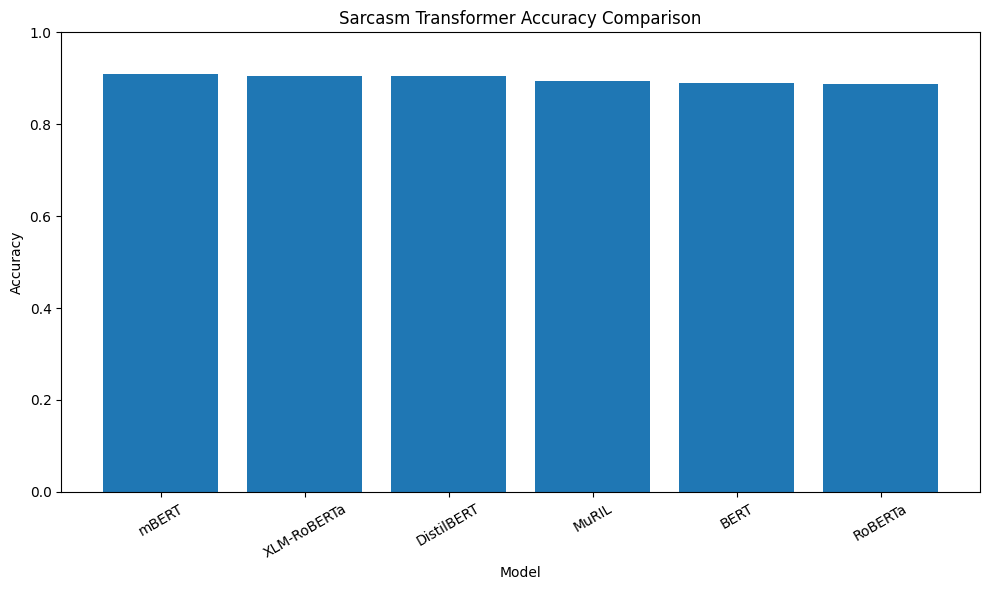

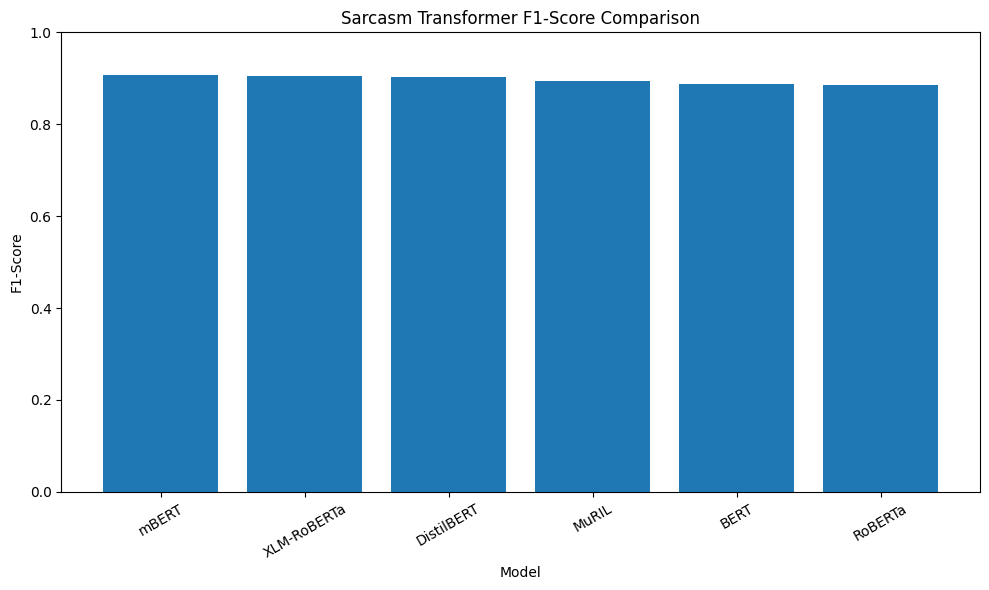


Comparison files created successfully!
CSV: ./sarcasm_transformer_results/comparison/sarcasm_transformer_comparison.csv
Accuracy graph: ./sarcasm_transformer_results/comparison/sarcasm_transformer_accuracy_comparison.png
F1 graph: ./sarcasm_transformer_results/comparison/sarcasm_transformer_f1_comparison.png


In [67]:
# Step 63: Create Final Sarcasm Transformer Comparison

import pandas as pd
import matplotlib.pyplot as plt
import os

# Final TEST results
sarcasm_results = pd.DataFrame({
    "Model": [
        "BERT",
        "mBERT",
        "RoBERTa",
        "XLM-RoBERTa",
        "MuRIL",
        "DistilBERT"
    ],
    "Accuracy": [
        0.8889,
        0.9083,
        0.8871,
        0.9048,
        0.8942,
        0.9048
    ],
    "Precision": [
        0.8961,
        0.9087,
        0.8985,
        0.9052,
        0.8943,
        0.9081
    ],
    "Recall": [
        0.8889,
        0.9083,
        0.8871,
        0.9048,
        0.8942,
        0.9048
    ],
    "F1-Score": [
        0.8870,
        0.9079,
        0.8846,
        0.9049,
        0.8938,
        0.9038
    ]
})

# Sort by F1-score
sarcasm_results = sarcasm_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# Rank
sarcasm_results.insert(
    0,
    "Rank",
    range(1, len(sarcasm_results) + 1)
)

print("===== FINAL SARCASM TRANSFORMER COMPARISON =====")
print(sarcasm_results.to_string(index=False))

# Best model
best_model = sarcasm_results.iloc[0]

print("\n===== BEST MODEL =====")
print("Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])

# Create output directory
comparison_dir = "./sarcasm_transformer_results/comparison"
os.makedirs(comparison_dir, exist_ok=True)

# Save CSV
csv_path = os.path.join(
    comparison_dir,
    "sarcasm_transformer_comparison.csv"
)

sarcasm_results.to_csv(csv_path, index=False)

# Accuracy graph
plt.figure(figsize=(10, 6))
plt.bar(
    sarcasm_results["Model"],
    sarcasm_results["Accuracy"]
)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Sarcasm Transformer Accuracy Comparison")
plt.xticks(rotation=30)
plt.tight_layout()

accuracy_path = os.path.join(
    comparison_dir,
    "sarcasm_transformer_accuracy_comparison.png"
)

plt.savefig(accuracy_path, dpi=300)
plt.show()

# F1 graph
plt.figure(figsize=(10, 6))
plt.bar(
    sarcasm_results["Model"],
    sarcasm_results["F1-Score"]
)
plt.ylim(0, 1)
plt.ylabel("F1-Score")
plt.xlabel("Model")
plt.title("Sarcasm Transformer F1-Score Comparison")
plt.xticks(rotation=30)
plt.tight_layout()

f1_path = os.path.join(
    comparison_dir,
    "sarcasm_transformer_f1_comparison.png"
)

plt.savefig(f1_path, dpi=300)
plt.show()

print("\nComparison files created successfully!")
print("CSV:", csv_path)
print("Accuracy graph:", accuracy_path)
print("F1 graph:", f1_path)

In [68]:
# Step 64: Verify all six saved models

import os

model_paths = {
    "BERT": "./sarcasm_bert_model",
    "mBERT": "./sarcasm_mbert_model",
    "RoBERTa": "./sarcasm_roberta_model",
    "XLM-RoBERTa": "./sarcasm_xlmr_model",
    "MuRIL": "./sarcasm_muril_model",
    "DistilBERT": "./sarcasm_distilbert_model"
}

print("===== SAVED MODEL CHECK =====\n")

for model_name, path in model_paths.items():
    if os.path.exists(path):
        files = os.listdir(path)
        print(f"✅ {model_name}: FOUND")
        print(f"   Location: {path}")
        print(f"   Files: {len(files)}")
    else:
        print(f"❌ {model_name}: NOT FOUND")

print("\n===== CHECK COMPLETE =====")

===== SAVED MODEL CHECK =====

✅ BERT: FOUND
   Location: ./sarcasm_bert_model
   Files: 5
✅ mBERT: FOUND
   Location: ./sarcasm_mbert_model
   Files: 5
✅ RoBERTa: FOUND
   Location: ./sarcasm_roberta_model
   Files: 5
✅ XLM-RoBERTa: FOUND
   Location: ./sarcasm_xlmr_model
   Files: 5
✅ MuRIL: FOUND
   Location: ./sarcasm_muril_model
   Files: 5
✅ DistilBERT: FOUND
   Location: ./sarcasm_distilbert_model
   Files: 5

===== CHECK COMPLETE =====


In [69]:
# Step 65: Create final organized folder and copy all models

import os
import shutil

base_dir = "./sarcasm_transformer_results"

models_dir = os.path.join(base_dir, "models")
comparison_dir = os.path.join(base_dir, "comparison")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(comparison_dir, exist_ok=True)

model_paths = {
    "BERT": "./sarcasm_bert_model",
    "mBERT": "./sarcasm_mbert_model",
    "RoBERTa": "./sarcasm_roberta_model",
    "XLM-RoBERTa": "./sarcasm_xlmr_model",
    "MuRIL": "./sarcasm_muril_model",
    "DistilBERT": "./sarcasm_distilbert_model"
}

print("===== COPYING MODELS =====\n")

for model_name, source_path in model_paths.items():

    destination = os.path.join(models_dir, model_name)

    if os.path.exists(destination):
        shutil.rmtree(destination)

    shutil.copytree(source_path, destination)

    print(f"✅ {model_name} copied")

print("\n===== ALL MODELS COPIED SUCCESSFULLY =====")

===== COPYING MODELS =====

✅ BERT copied
✅ mBERT copied
✅ RoBERTa copied
✅ XLM-RoBERTa copied
✅ MuRIL copied
✅ DistilBERT copied

===== ALL MODELS COPIED SUCCESSFULLY =====


✅ BERT confusion matrix saved
✅ mBERT confusion matrix saved
✅ RoBERTa confusion matrix saved
✅ XLM-RoBERTa confusion matrix saved
✅ MuRIL confusion matrix saved
✅ DistilBERT confusion matrix saved

✅ Comparison CSV saved


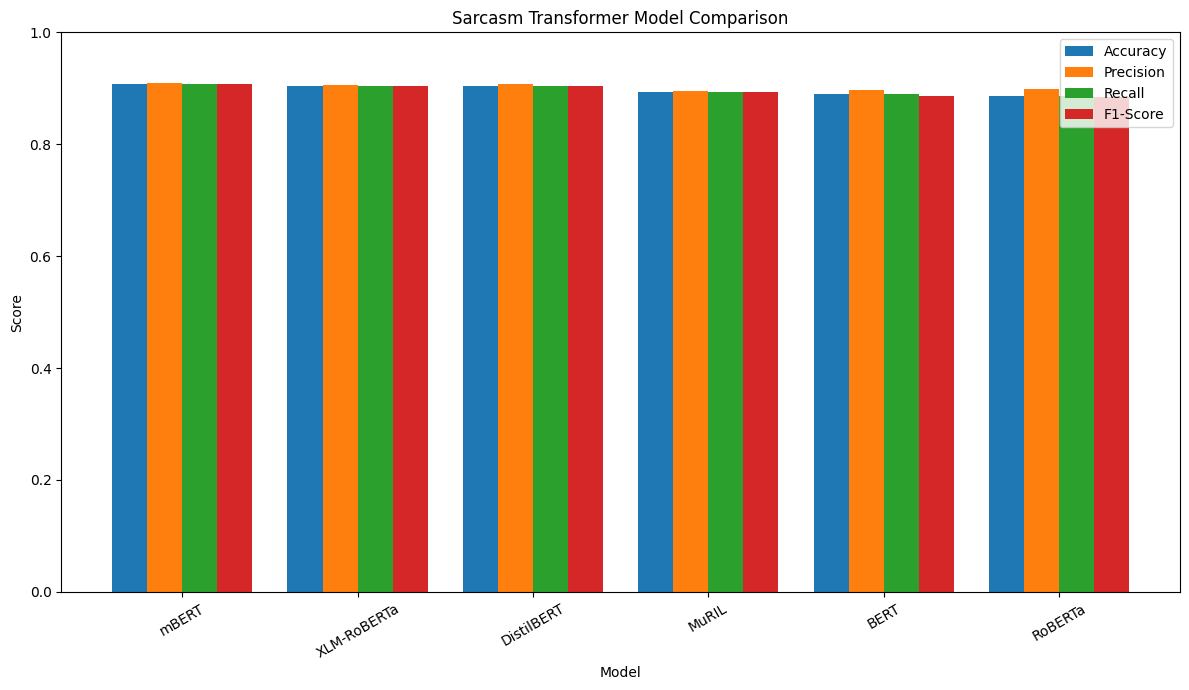

✅ Metrics comparison graph saved

===== FINAL MODEL RANKING =====

 Rank       Model  Accuracy  Precision  Recall  F1-Score
    1       mBERT    0.9083     0.9087  0.9083    0.9079
    2 XLM-RoBERTa    0.9048     0.9052  0.9048    0.9049
    3  DistilBERT    0.9048     0.9081  0.9048    0.9038
    4       MuRIL    0.8942     0.8943  0.8942    0.8938
    5        BERT    0.8889     0.8961  0.8889    0.8870
    6     RoBERTa    0.8871     0.8985  0.8871    0.8846

🏆 BEST MODEL: mBERT
Best F1: 0.9079
Best Accuracy: 0.9083

===== STEP 66 COMPLETE =====


In [70]:
# Step 66: Create Confusion Matrices and Final Comparison Files

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_dir = "./sarcasm_transformer_results"

comparison_dir = os.path.join(base_dir, "comparison")
cm_dir = os.path.join(base_dir, "confusion_matrices")

os.makedirs(comparison_dir, exist_ok=True)
os.makedirs(cm_dir, exist_ok=True)

# --------------------------------------------------
# 1. Store all confusion matrices
# --------------------------------------------------

confusion_matrices = {
    "BERT": bert_cm,
    "mBERT": np.array([[303, 19],
                       [33, 212]]),

    "RoBERTa": roberta_cm,

    "XLM-RoBERTa": xlmr_cm,

    "MuRIL": muril_cm,

    "DistilBERT": distilbert_cm
}

for model_name, cm in confusion_matrices.items():

    plt.figure(figsize=(6, 5))

    plt.imshow(cm)

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(
        [0, 1],
        ["Non-Sarcastic", "Sarcastic"]
    )

    plt.yticks(
        [0, 1],
        ["Non-Sarcastic", "Sarcastic"]
    )

    for i in range(2):
        for j in range(2):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()

    filename = model_name.replace("-", "_").replace(" ", "_")

    path = os.path.join(
        cm_dir,
        f"{filename}_confusion_matrix.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(f"✅ {model_name} confusion matrix saved")


# --------------------------------------------------
# 2. Final comparison dataframe
# --------------------------------------------------

results = pd.DataFrame({
    "Model": [
        "BERT",
        "mBERT",
        "RoBERTa",
        "XLM-RoBERTa",
        "MuRIL",
        "DistilBERT"
    ],

    "Accuracy": [
        0.8889,
        0.9083,
        0.8871,
        0.9048,
        0.8942,
        0.9048
    ],

    "Precision": [
        0.8961,
        0.9087,
        0.8985,
        0.9052,
        0.8943,
        0.9081
    ],

    "Recall": [
        0.8889,
        0.9083,
        0.8871,
        0.9048,
        0.8942,
        0.9048
    ],

    "F1-Score": [
        0.8870,
        0.9079,
        0.8846,
        0.9049,
        0.8938,
        0.9038
    ]
})

results = results.sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

results.insert(
    0,
    "Rank",
    range(1, len(results) + 1)
)

# Save final CSV
csv_path = os.path.join(
    comparison_dir,
    "sarcasm_transformer_comparison.csv"
)

results.to_csv(
    csv_path,
    index=False
)

print("\n✅ Comparison CSV saved")


# --------------------------------------------------
# 3. Accuracy / Precision / Recall / F1 graph
# --------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

plt.figure(figsize=(12, 7))

x = np.arange(len(results))
width = 0.2

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        results[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    results["Model"],
    rotation=30
)

plt.ylim(0, 1)

plt.ylabel("Score")
plt.xlabel("Model")

plt.title(
    "Sarcasm Transformer Model Comparison"
)

plt.legend()

plt.tight_layout()

metrics_path = os.path.join(
    comparison_dir,
    "sarcasm_transformer_metrics_comparison.png"
)

plt.savefig(
    metrics_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Metrics comparison graph saved")


# --------------------------------------------------
# 4. Print final ranking
# --------------------------------------------------

print("\n===== FINAL MODEL RANKING =====\n")

print(
    results.to_string(index=False)
)

print("\n🏆 BEST MODEL:", results.iloc[0]["Model"])
print(
    "Best F1:",
    f"{results.iloc[0]['F1-Score']:.4f}"
)
print(
    "Best Accuracy:",
    f"{results.iloc[0]['Accuracy']:.4f}"
)

print("\n===== STEP 66 COMPLETE =====")

In [71]:
# Step 67: Create README

import os
import zipfile

base_dir = "./sarcasm_transformer_results"

readme_content = """
SARCASM TRANSFORMER MODEL COMPARISON
====================================

Dataset
-------
Name: final_sarcasm_dataset.csv
Total samples: 5665

Labels:
0 = Non-Sarcastic
1 = Sarcastic

Dataset split:
Training: 4532
Validation: 566
Testing: 567

Models
------
1. BERT
2. mBERT
3. RoBERTa
4. XLM-RoBERTa
5. MuRIL
6. DistilBERT

Training Configuration
----------------------
Epochs: 3
Training batch size: 8
Learning rate: 2e-5
Maximum sequence length: 128

Final Test Results
------------------

Rank  Model           Accuracy   Precision   Recall   F1
1     mBERT           90.83%     90.87%      90.83%   90.79%
2     XLM-RoBERTa     90.48%     90.52%      90.48%   90.49%
3     DistilBERT      90.48%     90.81%      90.48%   90.38%
4     MuRIL           89.42%     89.43%      89.42%   89.38%
5     BERT            88.89%     89.61%      88.89%   88.70%
6     RoBERTa         88.71%     89.85%      88.71%   88.46%

Best Model
----------
mBERT

Accuracy: 90.83%
Precision: 90.87%
Recall: 90.83%
F1-Score: 90.79%

Conclusion
----------
Among the six evaluated Transformer models, mBERT achieved
the highest test accuracy and F1-score on the sarcasm dataset.

XLM-RoBERTa and DistilBERT achieved the next best overall
performance.

All six models were trained, evaluated on the same test set,
and saved in the models directory.

Directory Structure
-------------------
models/
    BERT/
    mBERT/
    RoBERTa/
    XLM-RoBERTa/
    MuRIL/
    DistilBERT/

comparison/
    sarcasm_transformer_comparison.csv
    sarcasm_transformer_metrics_comparison.png

confusion_matrices/
    Individual confusion matrix images for all six models.
"""

readme_path = os.path.join(base_dir, "README.txt")

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)

print("✅ README.txt created")
print("Location:", readme_path)


# Create ZIP
zip_path = "./sarcasm_transformer_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(base_dir):

        for file in files:

            full_path = os.path.join(root, file)

            arcname = os.path.relpath(
                full_path,
                os.path.dirname(base_dir)
            )

            zipf.write(
                full_path,
                arcname
            )

print("\n✅ FINAL ZIP CREATED")
print("Location:", zip_path)

# Check ZIP size
size_mb = os.path.getsize(zip_path) / (1024 * 1024)

print(f"ZIP size: {size_mb:.2f} MB")

✅ README.txt created
Location: ./sarcasm_transformer_results/README.txt

✅ FINAL ZIP CREATED
Location: ./sarcasm_transformer_results.zip
ZIP size: 3466.82 MB


In [72]:
from google.colab import files

files.download("/content/sarcasm_transformer_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>